**#1** Average inspection score by borough

In [3]:
import pandas as pd

id_dtypes = {
    "ZIPCODE": "string",
    "Community Board": "string",
    "Council District": "string",
    "Census Tract": "string",
    "BIN": "string",
    "BBL": "string",
}

df_prepared = pd.read_csv(
    "/Users/joshikaindrakumar/Documents/GitHub/nyc-restaurant-inspections-1/handoff/restaurants_prepared.csv",
    dtype=id_dtypes,
    parse_dates=["INSPECTION DATE", "GRADE DATE", "RECORD DATE"],
    low_memory=False,
)

inspection_key = ["CAMIS", "INSPECTION DATE", "INSPECTION TYPE"]
inspection_level_for_eda = (
    df_prepared.loc[~df_prepared["AWAITING_INSPECTION"]]
    .sort_values("SOURCE_ROW_ID", kind="stable")
    .drop_duplicates(subset=inspection_key, keep="first")
)

scored_inspections = inspection_level_for_eda.loc[
    inspection_level_for_eda["SCORE"].notna()
    & inspection_level_for_eda["BORO"].notna()
    & ~inspection_level_for_eda["BORO_UNKNOWN"]
]

borough_score_summary = (
    scored_inspections.groupby("BORO", as_index=False)
    .agg(
        inspection_count=("SCORE", "count"),
        average_score=("SCORE", "mean"),
    )
    .sort_values("BORO")
    .reset_index(drop=True)
)

borough_score_summary

,BORO,inspection_count,average_score
0,Bronx,7706,17.574358
1,Brooklyn,21412,17.972305
2,Manhattan,31393,17.205906
3,Queens,19429,19.192187
4,Staten Island,2922,16.870979


**Task 2** Score distribution (histogram/boxplot)


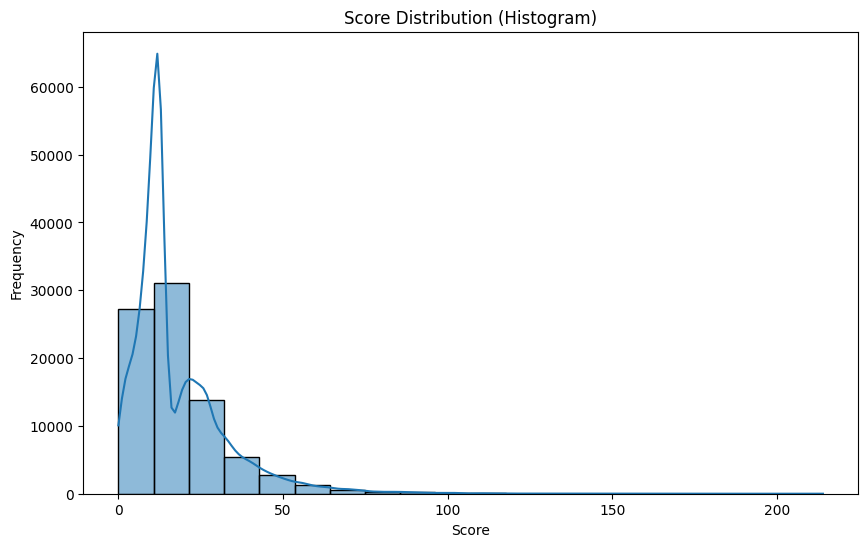

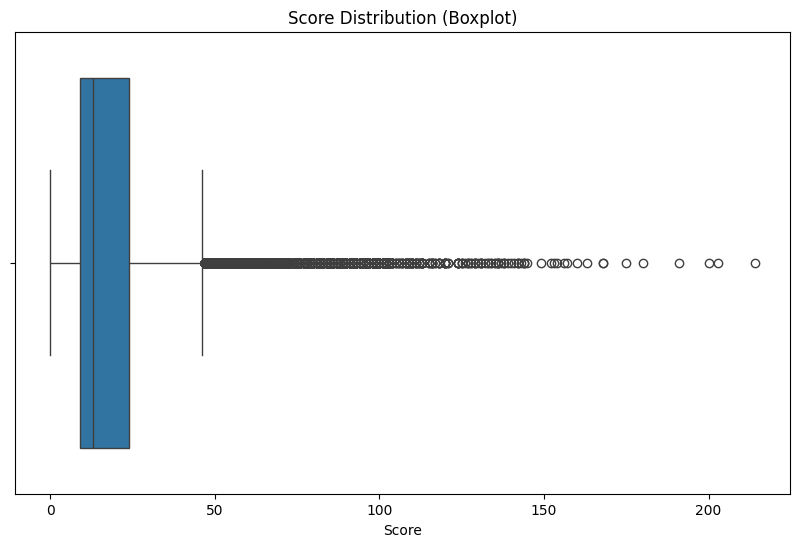

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Histogram
plt.figure(figsize=(10, 6))
sns.histplot(scored_inspections["SCORE"], bins=20, kde=True)
plt.title("Score Distribution (Histogram)")
plt.xlabel("Score")
plt.ylabel("Frequency")
plt.show()

# Boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(x="SCORE", data=scored_inspections)
plt.title("Score Distribution (Boxplot)")
plt.xlabel("Score")
plt.show()